# Goal geometry and task metrics

Research scratchpad 1/2. Can a better-looking latent metric select a better physical action? These are lightweight reanalyses of existing PushT evidence, not new experiments. The original team's proposal supplies the rank-32 contrastive adapter; this consolidation does not claim that idea.

Run all cells with Python 3.10, NumPy, pandas and Matplotlib. Keep evidence.zip and provenance.json beside this notebook. No checkpoint, simulator, local project imports, network calls or output-file writes are needed. Gains below mean baseline minus alternative physical regret, in pixel-equivalent units. Each study keeps its own cohort; differing absolute errors are not a leaderboard.

In [1]:
from pathlib import Path
from io import BytesIO
import hashlib, json, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Works from this folder or the repository root. Nothing is extracted or written.
HERE = (
    Path.cwd()
    if (Path.cwd() / "evidence.zip").is_file()
    else Path.cwd() / "auto_research"
)
provenance = json.loads((HERE / "provenance.json").read_text())
assert (
    hashlib.sha256((HERE / "evidence.zip").read_bytes()).hexdigest()
    == provenance["archive_sha256"]
)
archive = zipfile.ZipFile(HERE / "evidence.zip")
for item in provenance["files"]:
    assert (
        hashlib.sha256(archive.read(item["archive_path"])).hexdigest() == item["sha256"]
    )


def read_json(path):
    return json.loads(archive.read("docs/" + path))


def read_csv(path):
    return pd.read_csv(BytesIO(archive.read("docs/" + path)))


def read_arrays(path):
    # Materialize only this small archive; reject pickle-backed object arrays.
    with np.load(BytesIO(archive.read("docs/" + path)), allow_pickle=False) as saved:
        return {name: saved[name] for name in saved.files}


def paired_interval(matrix, seed):
    # Each row is a bank, each column a task. Repeated heads are averaged FIRST.
    matrix = np.asarray(matrix, float)
    assert matrix.ndim == 2 and min(matrix.shape) >= 2 and np.isfinite(matrix).all()
    banks, tasks = matrix.shape
    rng = np.random.default_rng(seed)
    chosen = rng.integers(banks, size=(10000, banks, 1))
    within = rng.integers(tasks, size=(10000, banks, tasks))
    draws = matrix[chosen, within].mean(axis=(1, 2))
    return np.array([matrix.mean(), *np.quantile(draws, [0.025, 0.975])])


def physical_error(poses, goal):
    position = np.linalg.norm(poses[..., :2] - goal[..., :2], axis=-1)
    angle = (poses[..., 2] - goal[..., 2] + np.pi) % (2 * np.pi) - np.pi
    return np.sqrt(position**2 + (50 * angle) ** 2)


plt.rcParams.update(
    {"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False}
)
print("Verified byte-identical evidence files:", len(provenance["files"]))
print("Source base:", provenance["base_revision"])


Verified byte-identical evidence files: 236
Source base: d07cd7878cb40ecbd9e1004ef7db6794eb08d1df


## 1. Averaging is not nuisance removal

Averaging squared distances to photos equals squared distance to their mean plus a candidate-independent constant. It still penalizes a candidate's nuisance coordinate. A quotient removes the span fitted to equivalent photos. The toy below is an algebra illustration only; lower latent cost is not evidence of better control. Equivalent-goal grouping is structured supervision.

In [2]:
goals = np.array([[0.0, -2.0], [0.0, -1.0], [0.0, 1.0], [0.0, 2.0]])
candidates = np.array([[0.0, 3.0], [1.0, 0.0]])
center = goals.mean(axis=0)
_, singular, vt = np.linalg.svd(goals - center, full_matrices=False)
basis = vt[singular > 1e-12].T
residual = candidates - center
prototype = np.square(residual).sum(axis=1)
quotient = prototype - np.square(residual @ basis).sum(axis=1)
assert prototype.argmin() == 1 and quotient.argmin() == 0
print(
    pd.DataFrame(
        {"task_error": [0.0, 1.0], "prototype": prototype, "quotient": quotient}
    )
)


   task_error  prototype      quotient
0         0.0        9.0  5.329071e-15
1         1.0        1.0  1.000000e+00


## 2. Goal quotient: unsupported primary, positive photo control

The fixed primary compares full global quotient with the same eight-photo prototype on 100 tasks in five banks. The patch variant was development-motivated and changes removable rank as well as locality. We retain its secondary negative/inconclusive result. Full protocol and reports are preserved in evidence.zip under docs/goal_quotient*.

In [3]:
tasks = read_csv("goal_quotient_results/task_rows.csv")
patch = read_csv("goal_quotient_results/patch_task_rows.csv")
primary_rows = tasks.query(
    "source == 'action_predicted' and goals == 8 and budget == 64"
)
wide = primary_rows.pivot(index=["seed", "task"], columns="method", values="regret")
assert wide.shape[0] == 100 and wide.index.get_level_values("seed").nunique() == 5
outcomes = []
for method in ["quotient_half", "quotient_full"]:
    delta = (wide.prototype - wide[method]).unstack("task")
    outcomes.append(
        [method, *paired_interval(delta, 491), int((delta.mean(axis=1) > 0).sum())]
    )
p = patch.query("source == 'action_predicted' and goals == 8 and budget == 64")
p = p.pivot(index=["seed", "task"], columns="method", values="regret")
delta = (p.prototype - p.patch_quotient).unstack("task")
outcomes.append(
    [
        "patch_quotient (secondary)",
        *paired_interval(delta, 491),
        int((delta.mean(axis=1) > 0).sum()),
    ]
)
photos = tasks.query(
    "source == 'action_predicted' and method == 'prototype' and budget == 64 and goals in [1,8]"
)
photos = photos.pivot(index=["seed", "task"], columns="goals", values="regret")
delta = (photos[1] - photos[8]).unstack("task")
outcomes.append(
    [
        "8 vs 1 photos (control)",
        *paired_interval(delta, 491),
        int((delta.mean(axis=1) > 0).sum()),
    ]
)
quotient_results = pd.DataFrame(
    outcomes, columns=["comparison", "gain", "lower95", "upper95", "positive_banks"]
)
print(quotient_results.round(4).to_string(index=False))
assert np.isclose(quotient_results.iloc[1].gain, -0.626, atol=0.001)
# Independently check selected physical labels against every saved state bank.
decisions = read_csv("goal_quotient_results/full_bank_decisions.csv")
for seed, group in decisions.groupby("seed"):
    saved = read_arrays(f"goal_quotient_results/state_banks/seed_{seed}.npz")
    poses = saved["candidate_states"][:, 2:5].reshape(-1, 64, 3)
    errors = physical_error(poses, saved["goal_poses"][:, None, :])
    for row in group.itertuples():
        actual = errors[row.task, row.selected_index]
        np.testing.assert_allclose(
            [row.selected_error, row.regret],
            [actual, actual - errors[row.task].min()],
            atol=1e-05,
            rtol=1e-06,
        )
print("Independent selected-error/regret checks:", len(decisions))


                comparison    gain  lower95  upper95  positive_banks
             quotient_half  0.0029  -0.3425   0.3787               2
             quotient_full -0.6262  -1.5515   0.0344               1
patch_quotient (secondary) -0.1506  -1.3205   0.7497               2
   8 vs 1 photos (control)  2.5487   1.5728   3.6466               5
Independent selected-error/regret checks: 1000


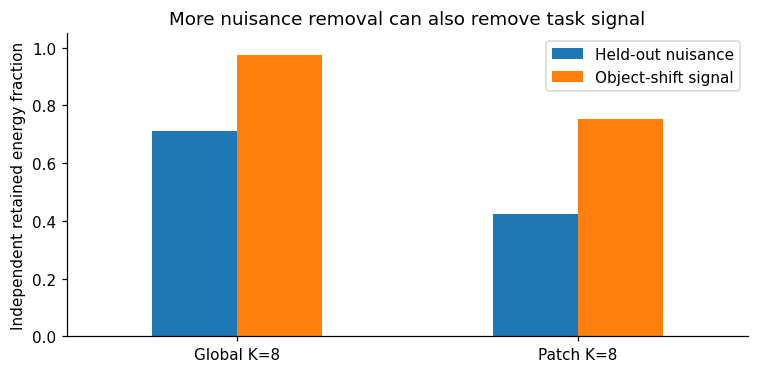

In [4]:
geometry = read_csv("goal_quotient_results/geometry.csv")
patch_geometry = read_csv("goal_quotient_results/patch_geometry.csv")
columns = ["heldout_nuisance_retained", "object_shift_signal_retained"]
comparison = pd.DataFrame(
    {
        "Global K=8": geometry.query("goals == 8")[columns].mean(),
        "Patch K=8": patch_geometry[columns].mean(),
    }
).T
comparison.rename(
    columns={
        "heldout_nuisance_retained": "Held-out nuisance",
        "object_shift_signal_retained": "Object-shift signal",
    }
).plot.bar(figsize=(7, 3.5), ylim=(0, 1.05), rot=0)
plt.ylabel("Independent retained energy fraction")
plt.title("More nuisance removal can also remove task signal")
plt.tight_layout()
plt.show()


The global primary gain is −0.626 [−1.551, +0.034]; unsupported, not proven equivalence or a definitive loss. Eight versus one photo gains +2.549 [1.573, 3.647]. The original prototype remains a strong control. The object-signal check is one x-shift, not all possible task changes.

## 3. Protected metric: geometry passed, physical gate failed

A constrained full-rank metric attenuates at most 32 nuisance directions while protecting calibration target distances. Passing finite image-geometry constraints does not guarantee preserved physical rankings. Three fixed heads are repeated measurements of 24 development tasks, not 72 independent tasks. The 100 reserved tasks remain unopened.

In [5]:
protected = read_csv("task_protected_metric_results/development/selections.csv")
view = protected.query(
    "goal_count == 8 and photo_set == 'main' and source == 'action_predicted'"
)
indices = view.query("method in ['prototype','protected']").pivot(
    index=["bank_seed", "task_id", "calibration_seed"],
    columns="method",
    values="selected_index",
)
assert len(indices) == 72 and (indices.prototype == indices.protected).all()
regret = view.pivot(
    index=["bank_seed", "task_id", "calibration_seed"],
    columns="method",
    values="regret",
)
# Separate selection per head, then equal-weight outcomes within each physical task.
per_task = regret.groupby(level=["bank_seed", "task_id"]).mean()
assert len(per_task) == 24
print(
    "Changed primary decisions:",
    int((indices.prototype != indices.protected).sum()),
    "/72",
)
print(
    "Protected mean regret gain:",
    float((per_task.prototype - per_task.protected).mean()),
)
print(
    "Exploratory adapter development gain:",
    float((per_task.prototype - per_task.adapter).mean()),
)
gate = read_json("task_protected_metric_results/gate.json")
assert gate["passed"] is False
print("Recorded gate checks:", gate["checks"])
print(
    pd.DataFrame(gate["validation"]["per_head"]).T[
        ["ratio_reduction", "median_local_retention", "p10_local_retention", "passed"]
    ]
)


Changed primary decisions: 0 /72
Protected mean regret gain: 0.0
Exploratory adapter development gain: 2.0139369964599614
Recorded gate checks: {'dev_effect': False, 'isotropic_rankings': True, 'no_leakage': True, 'nonfinite_free': True, 'numerical_tests': True, 'safe_rendering': True, 'solver_feasible': True, 'validation_geometry': True}
         ratio_reduction median_local_retention p10_local_retention passed
20264001        0.144318               0.953662            0.940401   True
20264002        0.143002               0.969797            0.956066   True
20264003        0.177966               0.974768             0.96003   True


Zero gain describes identical observed decisions, not population equivalence. The secondary adapter development gain motivated a separate fresh confirmation; it did not replace this failed primary.

## 4. Original adapter: fresh confirmation supported

The proposal's contrastive rank-32 head uses same/different-target supervision on frozen image features. Main-photo predicted regret is the sole primary comparison. The fixed gate requires gain ≥0.5, positive lower bound, ≥8 positive banks and positive aggregate gain for every head. The bootstrap averages the three fixed heads within each task and remains conditional on those fits. Initialization and shuffled-label controls are exploratory, not multiplicity-adjusted.

             reference   gain  lower95  upper95  positive_banks
             prototype 0.8544   0.1785   1.7669               9
adapter_initialization 1.0762   0.3553   1.9257               9
      shuffled_adapter 5.3223   3.4288   7.6876              10
Primary supported: True | head gains: {20264001: 0.6603, 20264002: 1.023, 20264003: 0.8797}
                        regret  selected_error
method                                        
adapter                 1.3338          8.3071
adapter_initialization  2.4100          9.3833
prototype               2.1882          9.1615
shuffled_adapter        6.6561         13.6294


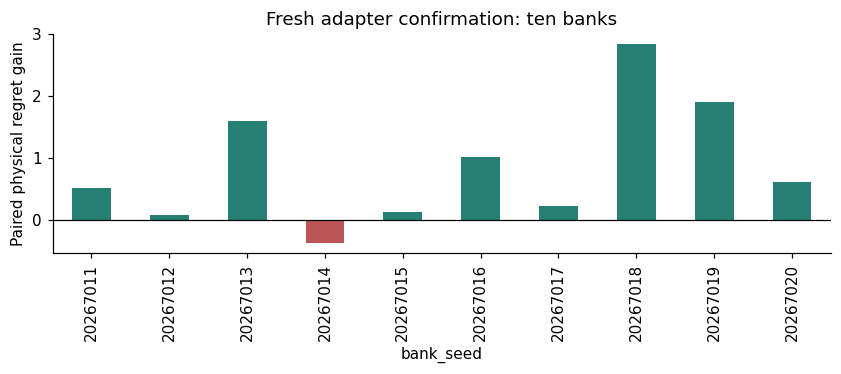

In [6]:
rows = read_csv("adapter_confirmation_results/selections.csv")
assert len(rows) == 100 * 3 * 4 * 2 * 2
main = rows.query("source == 'action_predicted' and photo_set == 'main'")
wide = main.pivot(
    index=["bank_seed", "task_id", "calibration_seed"],
    columns="method",
    values="regret",
)
assert len(wide) == 300 and (not wide.isna().any().any())
per_task = wide.groupby(level=["bank_seed", "task_id"]).mean()
assert len(per_task) == 100
results = []
for reference in ["prototype", "adapter_initialization", "shuffled_adapter"]:
    delta = (per_task[reference] - per_task.adapter).unstack("task_id")
    results.append(
        [
            reference,
            *paired_interval(delta, 20267901),
            int((delta.mean(axis=1) > 0).sum()),
        ]
    )
print(
    pd.DataFrame(
        results, columns=["reference", "gain", "lower95", "upper95", "positive_banks"]
    )
    .round(4)
    .to_string(index=False)
)
primary = results[0]
head_means = (wide.prototype - wide.adapter).groupby(level="calibration_seed").mean()
supported = (
    primary[1] >= 0.5
    and primary[2] > 0
    and (primary[4] >= 8)
    and (head_means > 0).all()
)
assert supported
saved = read_json("adapter_confirmation_results/summary.json")["primary"]
np.testing.assert_allclose(
    primary[1:4], [saved["mean_gain"], saved["lower_95"], saved["upper_95"]], atol=1e-10
)
print(
    "Primary supported:",
    bool(supported),
    "| head gains:",
    head_means.round(4).to_dict(),
)
print(main.groupby("method")[["regret", "selected_error"]].mean().round(4))
bank_gain = (per_task.prototype - per_task.adapter).groupby(level="bank_seed").mean()
bank_gain.plot.bar(
    figsize=(8, 3.5), color=np.where(bank_gain > 0, "#257f72", "#bc5656")
)
plt.axhline(0, color="black", lw=0.8)
plt.ylabel("Paired physical regret gain")
plt.title("Fresh adapter confirmation: ten banks")
plt.tight_layout()
plt.show()
archive.close()


## What to carry forward

The adapter gains +0.854 [0.179, 1.767] regret units. Regret falls 2.188 → 1.334, while selected error falls 9.162 → 8.307. A 39% regret reduction is **not** a 39% error reduction. Separate studies differ in target construction and wall conditioning; do not pool their absolute errors. The failed quotient and protected outcomes remain part of the evidence.

This is one released DINO-WM checkpoint, primarily one predicted step with five controls. It is not long-horizon or benchmark-level success. Local protocol freezes are not public preregistration; sequential hypotheses have no family-wide error control. Physical coordinates label evaluation, while simulator-designed equivalence groups are already structured supervision.

### Lineage and sources
- Original team proposal: rank-32 contrastive head, credited in the preserved adapter report and protocol.
- [DINO-WM](https://arxiv.org/html/2411.04983v2): frozen visual world-model baseline and existing planning evidence.
- Existing projection/metric-learning literature is reviewed in the preserved docs/goal_quotient_prior_art.md. No new projection principle is claimed.
- Exact source paths and SHA-256 hashes are in provenance.json. This selective bundle verifies the copied evidence, not unavailable historical endpoint bytes or full model replication.